<a href="https://colab.research.google.com/github/gyeongee/TIL/blob/main/%EB%AA%A8%EB%8D%B8%ED%8F%89%EA%B0%80%ED%95%98%EA%B8%B0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

이전 장까지는 우리는 어떻게 모델을 잘 학습시킬 것인지에 대해 배웠습니다.

이제는 이렇게 학습시킨 모델이 얼마나 잘 $f$를 잘 근사계산(approximate)하고 있는지 평가하는 방법에 대해서 이야기를 해보고자 합니다.

오버피팅을 피하는 방법에는 테스트 데이터셋을 통해 객관적인 평가를 수행하는 방법이 있습니다.

학습이 완료된 모델이 테스트 데이터셋에 대해 추론(inference)을 수행하고 나면 예측된 값(predicted value)을 실제 정답과 비교함으로써 모델의 성능을 알 수 있을 것입니다.

평가 방법에는 정성평가(intrinsic evaluation)와 정량평가(extrinsic evaluation)가 있습니다.

<table>
<thead>
<tr><td>방법</td><td>장점</td><td>특징</td></tr>
</thead>
<tbody>
<tr><td>정성평가</td><td>정확함</td><td>사람에 의한 채점 방식으로 채점 기준이 모호한 경우에 필수</td></tr>
<tr><td>정량평가</td><td>빠르고 정확함</td><td>컴퓨터에 의한 자동 채점됨.정성 평가와 비슷할수록 좋은 알고리즘</td></tr>
</tbody>
</table>

### 실무에서 평가가 진행되는 과정의 예



1.   학습이 완료된 모델에 테스트 데이터셋을 넣어 추론을 수행합니다.
2.   또한 동일한 테스트 데이터셋을 다른 베이스라인 모델에 넣어 추론을 수행합니다. 이때 베이스라인 모델의 코드를 가지고 있을 수도 있지만 경쟁사 서비스와 같이 코드가 없는 경우에는 직접 서비스에 데이터를 넣어 결과를 얻어올 수 있습니다.
3. 채점 기준이 모호한 경우에는 정성평가를 수행합니다. 이때 중요한 것은 누가 어떤 예측 결과를 내놓았는지를 가리고 평가하는 블라인드 테스트를 수행해야 한다는 점입니다. 만약 블라인드 테스트가 수행되지 않으면 이 테스트는 객관성을 갖추지 못했다고 볼 수 있습닏.
4. 미리 잘 정의된 정성평가 기준에 따라 평가가 완료되면 결과를 취합하여 보고합니다.


작은 개선 사항에 대해서는 주로 정량평가를 통해 성능을 평가하고 실제 서비스에 배포할 때 정성평가를 수행하는 것이 올바른 과정입니다.

### 오버피팅(overfiting)과 검증 데이터셋과 테스트 데이터
이제까지 우리는 학습 데이터로부터 손실 값을 구해서 모델의 학습 여부를 판단했습니다. 이를 다른 표현으로 학습 오차라고 부르기도 합니다.

데이터셋은 편향 또는 노이즈를 포함하고 있기도 합니다.

모델이 학습 데이터의 불필요한 특징까지 학습하여 오버피팅되는 것을 방지하기 위해 학습 데이터 일부를 임의로 나누어 검증 데이터셋으로 구성하고 이것을 학습하는 도중에 주기적으로 모델에 넣어 손실 값을 구함으로써 오버피팅 여부를 확인할 수 있습니다.





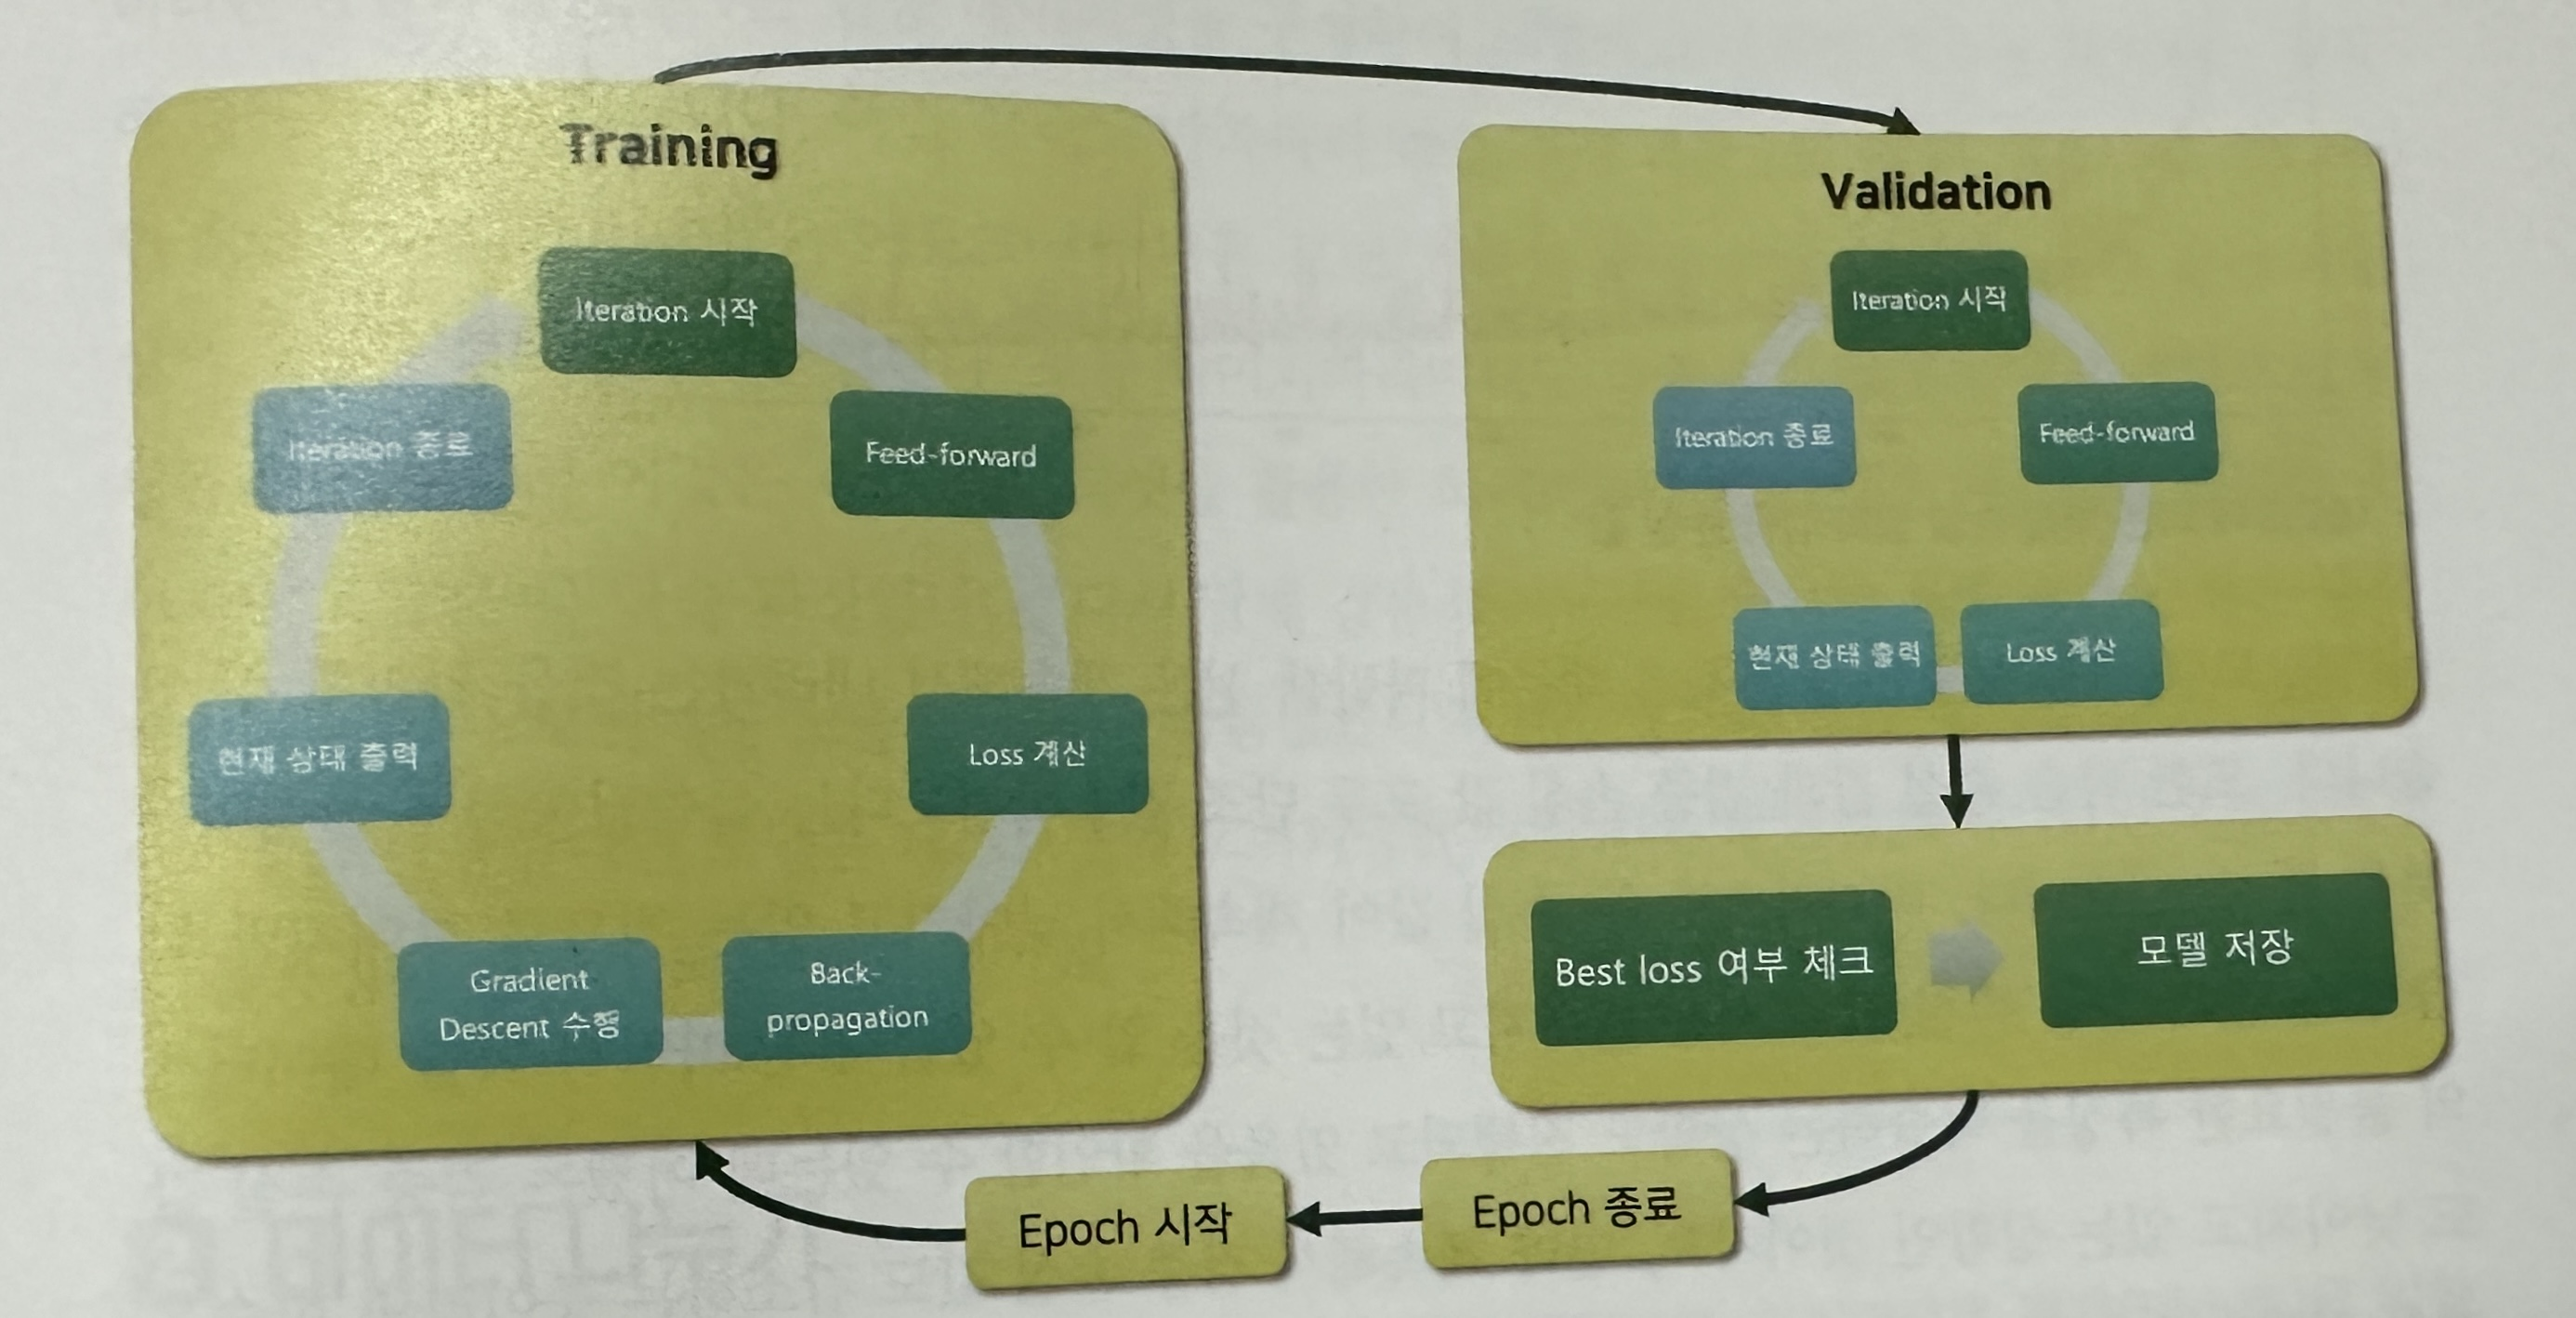

평가를 위한 테스트셋으로 검증 데이터 셋을 활용한다면 모델은 테스트셋에 오버피팅될 것입니다. 반면에 베이스라인 모델들에게는 불공평한 평가가 되는 셈인 것입니다.

따라서 최종적으로 학습을 휘한 데이터셋과 검증을 위한 데이터셋, 마지막으로 평가(테스트)를 위한 데이터셋을 따로 구성해야 합니다.

<table>
<thead>
<tr><td></td><td>Train set</td><td>Valid set</td><td>Test set</td></tr>
</thead>
<tbody>
<tr><td>Parameter</td><td>결정</td><td>검증</td><td>검증</td></tr>
<tr><td>Hyper-parameter</td><td></td><td>결정</td><td>검증</td></tr>
<tr><td>Algorithm</td><td></td><td></td><td>결정</td></tr>
</tbody>
</table>

학습 데이터셋을 통해 가중치 파라미터를 결정(학습)할 수 있으며, 검증 데이터셋과 테스트 데이터셋을 통해 오버피팅과 같은 정합성 여부를 확인할 수 있습니다. 하이퍼파라미터의 경우 경사하강법과 같은 최적화 방법을 통해 결정될 수 없기 떄문에 사용자에 의해 손으로 결정되는 작업이 수반되어야 합니다.

띠리사 대부분의 하이퍼파라미터들은 검증 데이터셋을 통해 결정되며 테스트셋을 통해서 검증을 수행할 수 있습니다.

알고리즘을 결정한다는 것은 여러 가지 베이스라인을 비롯한 모델 구조나 학습 기법 중에서 어떤 것이 가장 좋은지 결정하는 것을 의미합니다.  결국 테스트 데이터셋을 통한 평가를 통해 최고 성능의 알고리즘을 선택해야 하기 때문입니다.

### 사실 지금까지의 실습은 모두 잘못된 방법이었습니다.
단지 학습 데이터셋에 모델을 피팅시키면서 학습 손실 값만 살펴보았습니다. 또한 학습 데이터의 손실 값을 낮추고선, 모델의 성능을 확인한다고 손실 값이나 정확도를 확인하는 정도만 진행했었습니다.

하지만 이 장에서 배운 내용을 바탕으로 학습,검증,테스트 데이터를 잘 나누어 모델을 학습시키고 모델이 객관적으로 잘 학습되었는지 체크하는 실습을 수행할 것입니다.

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [26]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from tqdm import tqdm

In [27]:
from sklearn.datasets import fetch_california_housing

house=fetch_california_housing()

df=pd.DataFrame(data=house.data,columns=house.feature_names)
df['target']=house.target

df.head(3)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,target
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521


In [28]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MedInc      20640 non-null  float64
 1   HouseAge    20640 non-null  float64
 2   AveRooms    20640 non-null  float64
 3   AveBedrms   20640 non-null  float64
 4   Population  20640 non-null  float64
 5   AveOccup    20640 non-null  float64
 6   Latitude    20640 non-null  float64
 7   Longitude   20640 non-null  float64
 8   target      20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [29]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,target
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [30]:
# 정규화 진행
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
# target값 제외하고 정규화 진행
df.iloc[:,:-1]=scaler.fit_transform(df.iloc[:,:-1])
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,target
0,2.344766,0.982143,0.628559,-0.153758,-0.974429,-0.049597,1.052548,-1.327835,4.526
1,2.332238,-0.607019,0.327041,-0.263336,0.861439,-0.092512,1.043185,-1.322844,3.585
2,1.782699,1.856182,1.155620,-0.049016,-0.820777,-0.025843,1.038503,-1.332827,3.521
3,0.932968,1.856182,0.156966,-0.049833,-0.766028,-0.050329,1.038503,-1.337818,3.413
4,-0.012881,1.856182,0.344711,-0.032906,-0.759847,-0.085616,1.038503,-1.337818,3.422


In [31]:
from sklearn.model_selection import train_test_split
data=torch.from_numpy(df.values).float()

X=data[:,:-1]
y=data[:,-1:]

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=5)
X_train,X_valid,y_train,y_valid=train_test_split(X_train,y_train,test_size=0.25,random_state=5)

print(X_train.shape,X_valid.shape,X_test.shape)
print(y_train.shape,y_valid.shape,y_test.shape)

torch.Size([12384, 8]) torch.Size([4128, 8]) torch.Size([4128, 8])
torch.Size([12384, 1]) torch.Size([4128, 1]) torch.Size([4128, 1])


In [32]:
model=nn.Sequential(
    nn.Linear(X.size(-1),6),
    nn.LeakyReLU(),
    nn.Linear(6,5),
    nn.LeakyReLU(),
    nn.Linear(5,4),
    nn.LeakyReLU(),
    nn.Linear(4,3),
    nn.LeakyReLU(),
    nn.Linear(3,y.size(-1)),
)

학습률을 1e-3으로 지정해보겠습니다.

### 새로 추가하는 기능
- 과대적합 방지 기능
- 베스트 모델 저장 기능(BMC)
- 조기 학습 중단(Early Stopping)기능
- 검증데이터로 검증
- 테스트 데이터로 평가

In [52]:
n_epochs=40000
print_interval=200
batch_size=64
learning_rate=1e-3

In [53]:
optimizer=optim.Adam(model.parameters(),lr=learning_rate)
optimizer

Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)

- Best Model: 이전 epoch보다 개선된 모델(손실함수가 적은)이라면 해당 모델을 저장하고 최종 저장된 모델임을 의미

- Early Stopping : 설정된 epoch 이상 동안 손실함수가 감소하지 않으면 학습 중지

In [54]:
from copy import deepcopy
# 베스트 모델 저장
best_model=None

# 베스트 모델 판단을 위해 최소 손실값을 저장
#np.inf : 양의 무한대
# -np.inf: 음의 무한대
lowest_loss=np.inf

# 학습 중단에 필요한 대기 epoch 수
early_stop=200

# 학습 중단의 기준이 되는 최소 손실값을 갖는 epoch 저장
lowest_epoch = np.inf

### 학습과정
- 훈련데이터를 랜덤으로 섞어서 batch_size 만큼의 크기로 자름
- epoch마다 batch_size개씩 전체 데이터를 학습
- 검증 손실값이 최소 손실값보다 작다면 베스트 모델에 저장
- 일정 횟수(200번)이상 검증 손실값이 최소 손실값과 크다면 학습 중단

In [55]:
# epoch마다 학습/검증 손실값 저장하는  list
train_history,val_history=[],[]

for i in tqdm(range(n_epochs)):
  indices=torch.randperm(X_train.size(0))

  X_=torch.index_select(X_train,dim=0,index=indices)
  y_=torch.index_select(y_train,dim=0,index=indices)

  X_=X_.split(batch_size,dim=0)
  y_=y_.split(batch_size,dim=0)

  # 훈련데이터 손실,검증 데이터 손실 값 저장
  train_loss,val_loss=0,0
  # 예측값 저장
  pred_y=[]

  for X_i,y_i in zip(X_,y_):
    y_hat_i=model(X_i)
    loss=F.mse_loss(y_hat_i,y_i)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    # 현재 batch_size 데이터의 손실값을 더해주기
    train_loss+=float(loss)
  # 반복문을 빠져나와 현재 epoch에서의 평균 손실값을 저장
  train_loss=train_loss/len(X_)

  # 검증데이터에 대해 손실값 계산
  # 검증은 역전파 수행을 수행하지 않으므로 기울기를 초기화할 필요가 없다
  with torch.no_grad():
    X_=X_valid.split(batch_size,dim=0)
    y_=y_valid.split(batch_size,dim=0)

    for X_i,y_i in zip(X_,y_):
      y_hat_i=model(X_i)
      loss=F.mse_loss(y_hat_i,y_i)
      val_loss += loss
      pred_y+=[y_hat_i]

    # 반복문을 빠져 나와 평균 검정 손실 평균값을 valid loss에 다시 저장
    # val_loss는 현재 witj torch.no_grad() 안에서 작동 중
    # 즉 최적화 함수, 기울기를 구하지 않는 상태
    # tensor 연산 가능
    val_loss=val_loss/len(X_)

    # 훈련손실값과 검증 손실값을 리스트에 각각 저장
    train_history += [train_loss]
    val_history += [val_loss]

    if (i+1) % print_interval == 0:
      print(f'epoch : {i+1}, train_loss: {train_loss:.4e}, valid_loss: {val_loss:.4e}')

      # 검증 손실값이 최소손실값보다 작다면:
      if val_loss < lowest_loss:
      # 현재 검증 손실값은 최소 손실값보다 작으니 최소손실값으로 초기화
        lowest_loss=val_loss
        lowest_epoch = i

        # 현재 모델의 가중치값들을 복사
        # state_dict(): 각 계층의 가중치 + 편향을 반환한는 기능
        best_model=deepcopy(model.state_dict())
      else:
        # 조기학습중단
        if i > 0 and lowest_epoch + early_stop < i+1:
          print(f"{early_stop} epoch 동안 모델이 개선되지 않음")
          break

print(f"{lowest_epoch+1}epoch에서 가장 낮은 검증 손실값:{lowest_loss}")

# 베스트모델의 가중치(손실함수 값이 가장 작을 때)를 model에 초기화하기
# load_state_dict(): 모델을 불러올 때 사용하는 기능
model.load_state_dict(best_model)




  0%|          | 200/40000 [01:05<4:33:54,  2.42it/s]

epoch : 200, train_loss: 3.0755e-01, valid_loss: 3.1794e-01


  1%|          | 399/40000 [02:10<3:35:22,  3.06it/s]

epoch : 400, train_loss: 3.0602e-01, valid_loss: 3.1936e-01
200 epoch 동안 모델이 개선되지 않음
200epoch에서 가장 낮은 검증 손실값:0.31793972849845886


<All keys matched successfully>

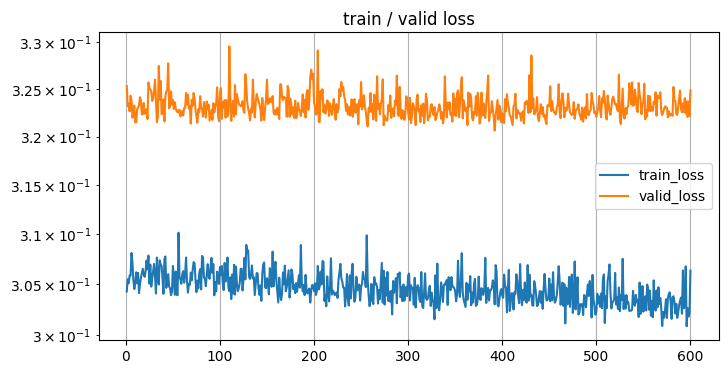

In [39]:
# 결과 시각화
# loss 값 선 그래프로 시각화
plt.figure(figsize=(8,4))
plt.grid()
plt.title('train / valid loss')

# 원하는 범위의 훈련,검증 손실값을 시각화
plt.plot(range(1,len(train_history)+1), train_history,label='train_loss')
plt.plot(range(1,len(val_history)+1), val_history,label='valid_loss')

plt.legend()
plt.yscale('log')
plt.show()

학습이 거의 진행되지 않은 상태로 보입니다.

batch_size를 64로 지정하고, `learinig_rate`을 1e-3으로 지정합니다.

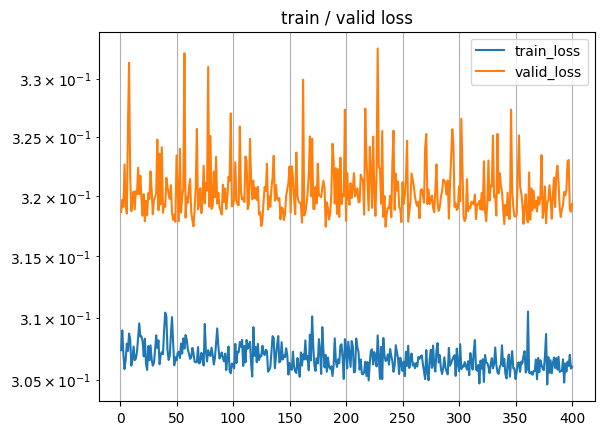

In [56]:
# batsize=64, learing_rate=1e-3 결과
plt.grid()
plt.title('train / valid loss')

# 원하는 범위의 훈련,검증 손실값을 시각화
plt.plot(range(1,len(train_history)+1), train_history,label='train_loss')
plt.plot(range(1,len(val_history)+1), val_history,label='valid_loss')

plt.legend()
plt.yscale('log')
plt.show()

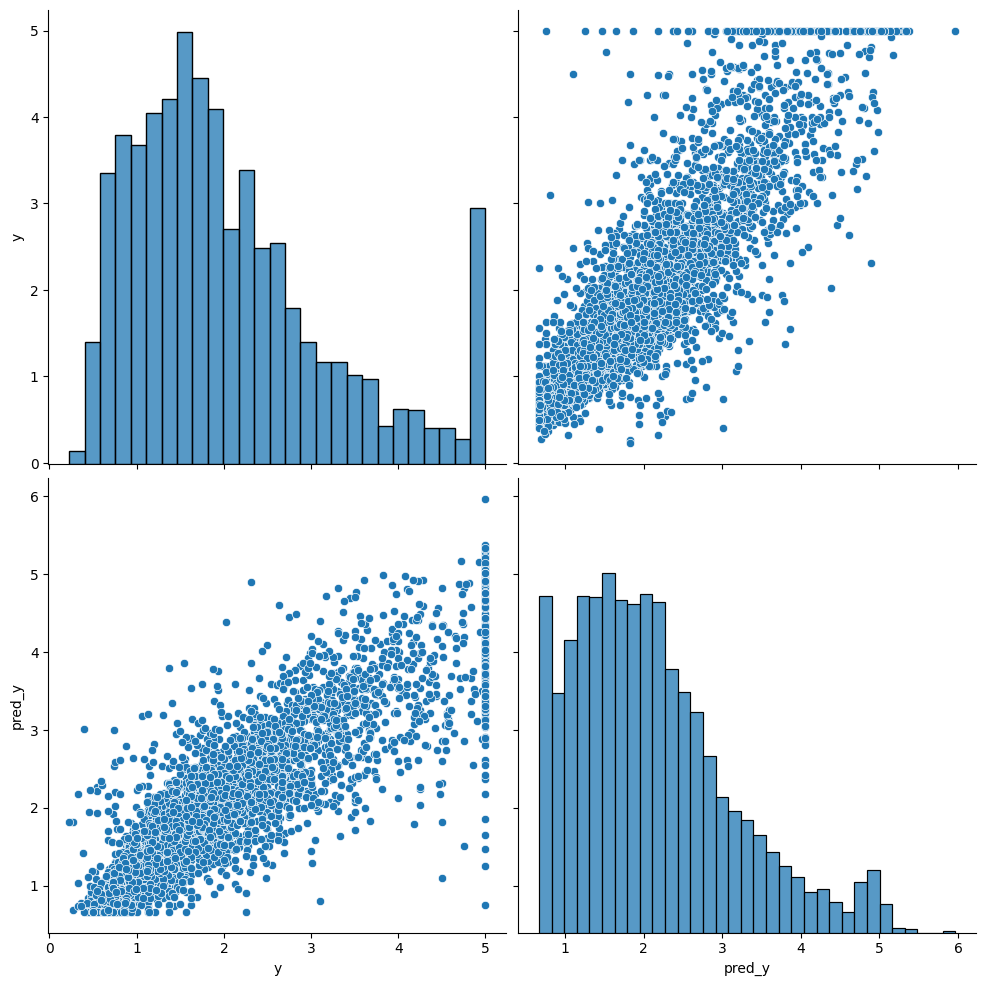

In [44]:
df = pd.DataFrame(torch.cat([y_valid, torch.cat(pred_y, dim=0)], dim=1).detach().numpy(),
                  columns=['y', 'pred_y'])
sns.pairplot(df, height=5)
plt.show()

### 테스트 데이터로 모델 성능 평가

In [61]:
test_loss=0
pred_y=[]

with torch.no_grad():
  X_=X_test.split(batch_size,dim=0)
  y_=y_test.split(batch_size,dim=0)

  for X_i,y_i in zip(X_,y_):
    pred_y_i=model(X_i)
    loss=F.mse_loss(pred_y_i,y_i)

    test_loss+= loss

    pred_y += [pred_y_i]

test_loss=test_loss / len(X_)
# 예측값들을 행방향으로 병합
pred_y=torch.cat(pred_y,dim=0)
pred_y

tensor([[1.3942],
        [2.0231],
        [1.5445],
        ...,
        [2.0403],
        [1.5809],
        [0.7157]])

In [62]:
#  가장 낮은 검증손실값과 학습손실값을 검색해서 결합
# train_history , val_history 값을 테스트 평가값과 함께 활용하기 위해서 데이터 정렬
# val_history를 기준으로 데이터 오름차순 정렬
sorted_history = sorted(zip(train_history,val_history),key = lambda x :x[1])
sorted_history

[(0.30649670032957166, tensor(0.3175)),
 (0.306982423994959, tensor(0.3175)),
 (0.3071279378281426, tensor(0.3175)),
 (0.3068662995530158, tensor(0.3175)),
 (0.3066615108976659, tensor(0.3177)),
 (0.30689723382598344, tensor(0.3177)),
 (0.3086670407468511, tensor(0.3177)),
 (0.3061351965075916, tensor(0.3178)),
 (0.31047967736868515, tensor(0.3178)),
 (0.30626598215594736, tensor(0.3178)),
 (0.30772453692463253, tensor(0.3179)),
 (0.3068023651991923, tensor(0.3179)),
 (0.30828575932027136, tensor(0.3179)),
 (0.307235011542888, tensor(0.3179)),
 (0.3063837417314962, tensor(0.3179)),
 (0.30640817986628444, tensor(0.3179)),
 (0.3075491988781801, tensor(0.3179)),
 (0.3075418307532355, tensor(0.3180)),
 (0.30693551748222914, tensor(0.3180)),
 (0.3077211727186577, tensor(0.3180)),
 (0.30796211439463284, tensor(0.3180)),
 (0.3054972584023304, tensor(0.3180)),
 (0.3057912313139316, tensor(0.3181)),
 (0.30603188291652916, tensor(0.3181)),
 (0.3065237558840476, tensor(0.3181)),
 (0.3058233900168

In [63]:
# test_loss값과 train_loss, valid_loss 비교
print(f"train loss: {sorted_history[0][0]:.4e}")
print(f"valid loss: {sorted_history[0][1]:.4e}")
print(f"test loss: {test_loss:.4e}")

train loss: 3.0650e-01
valid loss: 3.1745e-01
test loss: 3.1453e-01


###결과
- 전반적으로 오차가 0.3에서 머무르고 있음
- train, valid , test 오차가 크게 차이나지 않으므로 모델의 일반화 성능은 나름대로 확보되고 있음

- 모델이 깊이. 모델 내부의 뉴런 개수 등에 따라서 더 좋은 성능의 모델로 발전시켜보도록 노력이 필요
- 과대적합을 더 제어하면서 모델의 성능을 높이자

모델이 제대로 작동하기 위해서는 일반화가 잘 되었는지 확인하는 것이 중요합니다.